<a href="https://colab.research.google.com/github/lauravazqx/stochastic-simulation/blob/main/Tarea_3_SE.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Tarea 3. Simulación Estocástica.**


## Laura T. Salvador Vazquez.


*En esta sección se encontrarán los códigos necesarios implementados para la solución de los ejercicios de la Tarea 3 que lo hayan requerido.*

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mpmath import mp, mpf, quad, log

# Ejercicio 1.2. Simulación.

1000 experimentos Monte-Carlo, tanto para el método crudo y antitético con método de la transformación inversa.

Integral = 0.14175
Cov(Y1,Y2) = -3.8583,  rho = -0.1929,  1+rho = 0.8071
  n  Var crudo (emp.)  Var antit. (emp.)  Var crudo (teór.)  Var antit. (teór.)  Razón emp. (antit./crudo)
  2           12.0362             9.1824            10.0000              8.0709                     0.7629
  3            6.6769             5.7190             6.6667              5.8093                     0.8565
 10            1.7584             1.3482             2.0000              1.6142                     0.7667
 11            1.9627             1.4570             1.8182              1.4993                     0.7423
 50            0.4215             0.2951             0.4000              0.3228                     0.7001
 51            0.4081             0.3397             0.3922              0.3180                     0.8323
100            0.1907             0.1639             0.2000              0.1614                     0.8596

--- Resumen ---
Media de las estimaciones (crudo):      1.9990  (verda

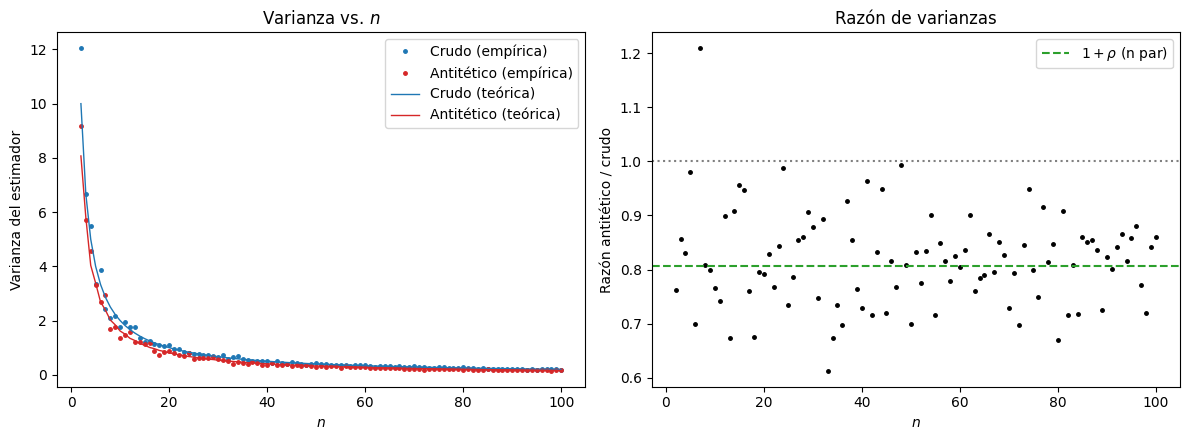

In [3]:


# ----------------------------------------------------------
# Configuración del problema
# f: densidad Exp(1),  F^{-1}(u) = -ln(1-u),  h(x) = x^2
# E_f[h(X)] = 2
# ----------------------------------------------------------
rng = np.random.default_rng(2026)

Finv = lambda u: -np.log(1.0 - u)   # inversa de la CDF de Exp(1)
h = lambda x: x**2                  # función h (no decreciente en (0, inf))
theta = 2.0                         # valor verdadero de E_f[h(X)]

N_EXP = 1000                        # experimentos de Monte Carlo por cada n
ns = np.arange(2, 101)              # n = 2, 3, ..., 100

# ----------------------------------------------------------
# Simulación
# ----------------------------------------------------------
var_crudo, var_anti = [], []
media_crudo, media_anti = [], []

for n in ns:
    m = n // 2   # número de pares antitéticos

    # Método crudo: n simulaciones iid por experimento
    U = rng.random((N_EXP, n))
    est_crudo = h(Finv(U)).mean(axis=1)

    # Método antitético: m pares (U, 1-U) + 1 simulación extra si n es impar
    V = rng.random((N_EXP, m))
    suma = (h(Finv(V)) + h(Finv(1 - V))).sum(axis=1)
    if n % 2 == 1:
        suma = suma + h(Finv(rng.random(N_EXP)))
    est_anti = suma / n

    var_crudo.append(est_crudo.var(ddof=1))
    var_anti.append(est_anti.var(ddof=1))
    media_crudo.append(est_crudo.mean())
    media_anti.append(est_anti.mean())

var_crudo = np.array(var_crudo)
var_anti = np.array(var_anti)

# ----------------------------------------------------------
# Varianzas teóricas
# ----------------------------------------------------------
mp.dps = 30
sigma2 = 20.0                                              # Var(X^2) = 24 - 4
integral = quad(lambda u: log(u)**2 * log(1 - u)**2, [0, 1])
cov = float(integral) - theta**2                           # Cov(Y1, Y2)
rho = cov / sigma2
print(f"Integral = {float(integral):.5f}")
print(f"Cov(Y1,Y2) = {cov:.4f},  rho = {rho:.4f},  1+rho = {1+rho:.4f}")

teo_crudo = sigma2 / ns
teo_anti = np.where(
    ns % 2 == 0,
    sigma2 * (1 + rho) / ns,
    sigma2 * ((ns - 1) * (1 + rho) + 1) / ns**2,
)

# ----------------------------------------------------------
# Tabla comparativa
# ----------------------------------------------------------
tabla = pd.DataFrame({
    "n": ns,
    "Var crudo (emp.)": var_crudo,
    "Var antit. (emp.)": var_anti,
    "Var crudo (teór.)": teo_crudo,
    "Var antit. (teór.)": teo_anti,
    "Razón emp. (antit./crudo)": var_anti / var_crudo,
})
print(tabla.round(4).iloc[[0, 1, 8, 9, 48, 49, 98]].to_string(index=False))

# ----------------------------------------------------------
# Resumen
# ----------------------------------------------------------
razon = var_anti / var_crudo
print("\n--- Resumen ---")
print(f"Media de las estimaciones (crudo):      {np.mean(media_crudo):.4f}  (verdadero = {theta})")
print(f"Media de las estimaciones (antitético): {np.mean(media_anti):.4f}  (verdadero = {theta})")
print(f"Promedio de n*Var (crudo):      {np.mean(ns * var_crudo):.3f}  (teórico = {sigma2})")
print(f"Promedio de n*Var (antitético): {np.mean(ns * var_anti):.3f}")
print(f"Razón promedio antit./crudo: {razon.mean():.3f}  (teórico n par = {1+rho:.3f})")
print(f"Valores de n con Var antit. < Var crudo: {(var_anti < var_crudo).sum()} de {len(ns)}")

# ----------------------------------------------------------
# Gráficas
# ----------------------------------------------------------
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))

ax[0].plot(ns, var_crudo, ".", ms=5, color="C0", label="Crudo (empírica)")
ax[0].plot(ns, var_anti, ".", ms=5, color="C3", label="Antitético (empírica)")
ax[0].plot(ns, teo_crudo, "-", lw=1, color="C0", label="Crudo (teórica)")
ax[0].plot(ns, teo_anti, "-", lw=1, color="C3", label="Antitético (teórica)")
ax[0].set_xlabel("$n$")
ax[0].set_ylabel("Varianza del estimador")
ax[0].set_title("Varianza vs. $n$")
ax[0].legend()

ax[1].plot(ns, razon, ".", ms=5, color="k")
ax[1].axhline(1 + rho, color="C2", ls="--", label=r"$1+\rho$ (n par)")
ax[1].axhline(1, color="gray", ls=":")
ax[1].set_xlabel("$n$")
ax[1].set_ylabel("Razón antitético / crudo")
ax[1].set_title("Razón de varianzas")
ax[1].legend()

plt.tight_layout()
plt.show()

# Ejercicio 2. Monte-Carlo estratificado.

Vía Monte-Carlo crudo.

Valor verdadero de la integral: 1.71828

            Método   n_s      Media  Var empírica  Var teórica  Razón emp. vs crudo
             Crudo     - 1.7164e+00    5.0482e-04   4.8407e-04           1.0000e+00
 Estratificado S=2   250 1.7187e+00    1.3001e-04   1.2986e-04           2.5754e-01
 Estratificado S=4   125 1.7182e+00    3.0792e-05   3.3070e-05           6.0996e-02
 Estratificado S=8 62-63 1.7183e+00    7.7499e-06   8.3373e-06           1.5352e-02
Estratificado S=16 31-32 1.7183e+00    2.0206e-06   2.0891e-06           4.0026e-03


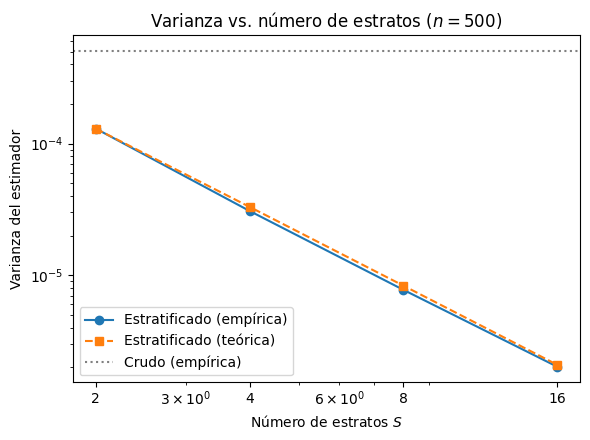

In [4]:


# ----------------------------------------------------------
# Configuración
# h(x) = e^x en [0,1];  I = integral de h = e - 1
# ----------------------------------------------------------
rng = np.random.default_rng(2026)

h = lambda x: np.exp(x)
I_true = np.e - 1

n = 500                      # simulaciones por experimento
N_EXP = 1000                 # número de experimentos Monte-Carlo
S_list = [2, 4, 8, 16]       # número de estratos

sigma2 = (np.e**2 - 1) / 2 - I_true**2   # Var(h(X)), X ~ U(0,1)


def asignacion(n, S):
    """Tamaños n_s por estrato; si S no divide a n, los r = n mod S
    primeros estratos reciben un punto extra."""
    base, r = divmod(n, S)
    return np.array([base + (1 if s < r else 0) for s in range(S)])


def sigma2_estratos(S):
    """Varianza teórica de h(X) dentro de cada estrato de [0,1] (X uniforme en el estrato)."""
    a = np.arange(S) / S
    b = (np.arange(S) + 1) / S
    mu = S * (np.exp(b) - np.exp(a))
    m2 = S * (np.exp(2 * b) - np.exp(2 * a)) / 2
    return m2 - mu**2


# ----------------------------------------------------------
# Monte-Carlo crudo
# ----------------------------------------------------------
est_crudo = h(rng.random((N_EXP, n))).mean(axis=1)

resultados = [{
    "Método": "Crudo",
    "n_s": "-",
    "Media": est_crudo.mean(),
    "Var empírica": est_crudo.var(ddof=1),
    "Var teórica": sigma2 / n,
}]
var_crudo_emp = est_crudo.var(ddof=1)

# ----------------------------------------------------------
# Monte-Carlo estratificado
# ----------------------------------------------------------
for S in S_list:
    ns = asignacion(n, S)
    est = np.zeros(N_EXP)
    for s in range(S):
        U = rng.random((N_EXP, ns[s]))
        X = (s + U) / S                      # uniforme en [s/S, (s+1)/S)
        est += (1 / S) * h(X).mean(axis=1)   # p_s * media del estrato

    var_teo = np.sum((1 / S) ** 2 * sigma2_estratos(S) / ns)
    tam = f"{ns.min()}" if ns.min() == ns.max() else f"{ns.min()}-{ns.max()}"
    resultados.append({
        "Método": f"Estratificado S={S}",
        "n_s": tam,
        "Media": est.mean(),
        "Var empírica": est.var(ddof=1),
        "Var teórica": var_teo,
    })

# ----------------------------------------------------------
# Tabla de resultados
# ----------------------------------------------------------
tabla = pd.DataFrame(resultados)
tabla["Razón emp. vs crudo"] = tabla["Var empírica"] / var_crudo_emp

pd.set_option("display.float_format", lambda x: f"{x:.4e}")
print(f"Valor verdadero de la integral: {I_true:.5f}\n")
print(tabla.to_string(index=False))

# ----------------------------------------------------------
# Gráfica: varianza vs. número de estratos
# ----------------------------------------------------------
S_vals = np.array(S_list)
var_emp = tabla["Var empírica"].values[1:].astype(float)
var_teo = tabla["Var teórica"].values[1:].astype(float)

plt.figure(figsize=(6, 4.5))
plt.loglog(S_vals, var_emp, "o-", label="Estratificado (empírica)")
plt.loglog(S_vals, var_teo, "s--", label="Estratificado (teórica)")
plt.axhline(var_crudo_emp, color="gray", ls=":", label="Crudo (empírica)")
plt.xlabel("Número de estratos $S$")
plt.ylabel("Varianza del estimador")
plt.xticks(S_vals, S_vals)
plt.legend()
plt.title("Varianza vs. número de estratos ($n=500$)")
plt.tight_layout()
plt.show()

# Ejercicio 4. Estimadores Monte-Carlo y Rao-Blackwellización.

Programe y compare estos estimadores para

$$
\mathbb{E}_{g_X}[X]
\qquad \text{y} \qquad
\operatorname{Var}_{g_X}(X)
$$

con

$$
X \mid Y=y \sim \operatorname{Normal}(0,y),
\qquad
Y^{-1} \sim \operatorname{Gamma}(1,1).
$$

=== 1. Verificación X ~ t_2 ===
KS: estadístico = 0.00111, p-valor = 0.166
E|X| muestral = 1.4199   (teórico = sqrt(2) = 1.4142)

=== 2. Trayectoria única (alpha = 1) ===
n =     100:  E[X] crudo =  0.4807 | Var crudo = 17.029 | Var RB = 11.952
n =    1000:  E[X] crudo =  0.0285 | Var crudo = 5.931 | Var RB = 8.967
n =   10000:  E[X] crudo =  0.0344 | Var crudo = 9.252 | Var RB = 12.479
n =  100000:  E[X] crudo =  0.0486 | Var crudo = 17.770 | Var RB = 14.252
n = 1000000:  E[X] crudo =  0.0049 | Var crudo = 13.574 | Var RB = 16.356


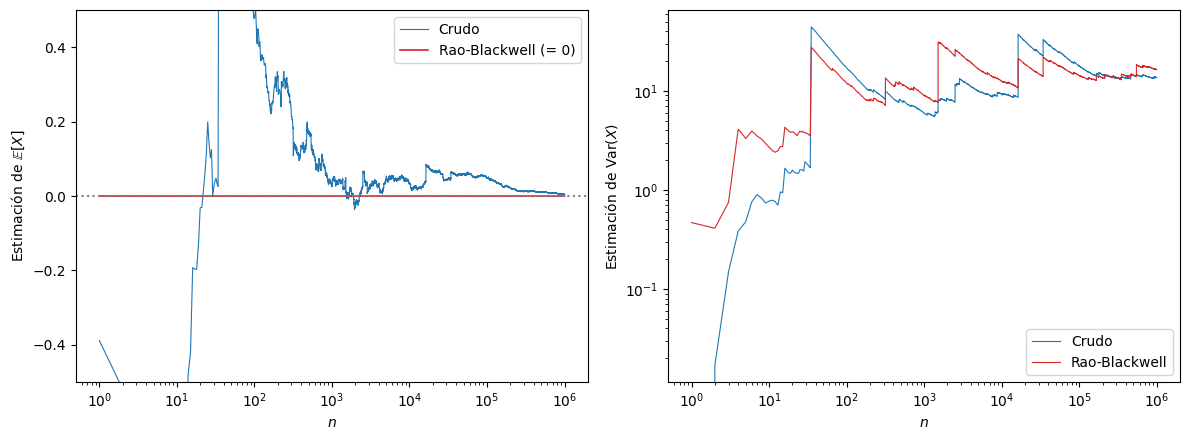


=== 3. Réplicas, alpha = 1 (Var(X) infinita) ===
    n  Var emp. E[X] crudo  Mediana |error| E[X] crudo  E[X] RB  Mediana Var(X) crudo  Mediana Var(X) RB
  100               0.1066                      0.1809        0                 5.014              5.682
 1000              0.01189                     0.06667        0                 7.341              8.117
10000             0.001723                     0.02274        0                 9.683               10.5

=== 4. Variante alpha = 3: Var(X) = 0.5, Var(X^2) = 1.25, Var(Y) = 0.25 ===
    n  E[X] crudo emp  E[X] crudo teór  Var(X) crudo emp  Var(X) crudo teór  Var(X) RB emp  Var(X) RB teór  Razón RB/crudo
  100        0.004932            0.005           0.01177             0.0125       0.002916          0.0025          0.2478
 1000       0.0004966           0.0005          0.001134            0.00125      0.0002404         0.00025          0.2119
10000       4.752e-05            5e-05         0.0001253           0.000125       2.

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

rng = np.random.default_rng(2026)


# ----------------------------------------------------------
# Simulación del modelo jerárquico
#   1/Y ~ Gamma(alpha, 1),   X | Y=y ~ Normal(0, varianza = y)
# ----------------------------------------------------------
def simular(alpha, size):
    tau = rng.gamma(shape=alpha, scale=1.0, size=size)   # tau = 1/Y
    Y = 1.0 / tau
    X = rng.normal(loc=0.0, scale=np.sqrt(Y))            # varianza = Y
    return X, Y


# ----------------------------------------------------------
# 1. Verificación de la pista: X ~ t de Student con 2 g.l. (alpha = 1)
# ----------------------------------------------------------
X, Y = simular(1.0, 10**6)
ks = stats.kstest(X, "t", args=(2,))
print("=== 1. Verificación X ~ t_2 ===")
print(f"KS: estadístico = {ks.statistic:.5f}, p-valor = {ks.pvalue:.3f}")
print(f"E|X| muestral = {np.abs(X).mean():.4f}   (teórico = sqrt(2) = {np.sqrt(2):.4f})")

# ----------------------------------------------------------
# 2. Una trayectoria larga (alpha = 1): estimaciones en función de n
#    Crudo:  media = mean(X),  var = mean(X^2) - mean(X)^2
#    RB:     E[X|Y] = 0, E[X^2|Y] = Y  ->  media = 0,  var = mean(Y)
# ----------------------------------------------------------
nmax = 10**6
X, Y = simular(1.0, nmax)
k = np.arange(1, nmax + 1)

m_crudo = np.cumsum(X) / k
v_crudo = np.cumsum(X**2) / k - m_crudo**2
m_rb = np.zeros(nmax)
v_rb = np.cumsum(Y) / k - m_rb**2

print("\n=== 2. Trayectoria única (alpha = 1) ===")
for kk in [10**2, 10**3, 10**4, 10**5, 10**6]:
    print(f"n = {kk:>7}:  E[X] crudo = {m_crudo[kk-1]: .4f} | "
          f"Var crudo = {v_crudo[kk-1]:.3f} | Var RB = {v_rb[kk-1]:.3f}")

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].semilogx(k, m_crudo, color="C0", lw=0.8, label="Crudo")
ax[0].semilogx(k, m_rb, color="C3", lw=1.2, label="Rao-Blackwell (= 0)")
ax[0].axhline(0, color="gray", ls=":")
ax[0].set_ylim(-0.5, 0.5)
ax[0].set_xlabel("$n$")
ax[0].set_ylabel(r"Estimación de $\mathbb{E}[X]$")
ax[0].legend()

ax[1].loglog(k, v_crudo, color="C0", lw=0.8, label="Crudo")
ax[1].loglog(k, v_rb, color="C3", lw=0.8, label="Rao-Blackwell")
ax[1].set_xlabel("$n$")
ax[1].set_ylabel(r"Estimación de $\mathrm{Var}(X)$")
ax[1].legend()
plt.tight_layout()
plt.savefig("trayectoria.png", dpi=200)
plt.show()

# ----------------------------------------------------------
# 3. Réplicas para alpha = 1 (Var(X) = infinito)
# ----------------------------------------------------------
N_EXP = 1000
filas = []
for n in [100, 1000, 10000]:
    X, Y = simular(1.0, (N_EXP, n))
    m = X.mean(axis=1)
    vc = (X**2).mean(axis=1) - m**2
    vr = Y.mean(axis=1)
    filas.append({
        "n": n,
        "Var emp. E[X] crudo": m.var(ddof=1),
        "Mediana |error| E[X] crudo": np.median(np.abs(m)),
        "E[X] RB": 0.0,
        "Mediana Var(X) crudo": np.median(vc),
        "Mediana Var(X) RB": np.median(vr),
    })
print("\n=== 3. Réplicas, alpha = 1 (Var(X) infinita) ===")
print(pd.DataFrame(filas).to_string(index=False, float_format=lambda x: f"{x:.4g}"))

# ----------------------------------------------------------
# 4. Variante complementaria: alpha = 3 (Var(X) = 1/2 finita)
# ----------------------------------------------------------
alpha = 3.0
sig2 = 1 / (alpha - 1)                            # Var(X) = E[Y]
EX4 = 3 / ((alpha - 1) * (alpha - 2))             # E[X^4] = 3 E[Y^2]
var_X2 = EX4 - sig2**2                            # Var(X^2)
var_Y = 1 / ((alpha - 1)**2 * (alpha - 2))        # Var(Y)
print(f"\n=== 4. Variante alpha = 3: Var(X) = {sig2}, Var(X^2) = {var_X2}, Var(Y) = {var_Y} ===")

filas = []
for n in [100, 1000, 10000]:
    X, Y = simular(alpha, (N_EXP, n))
    m = X.mean(axis=1)
    vc = (X**2).mean(axis=1) - m**2
    vr = Y.mean(axis=1)
    filas.append({
        "n": n,
        "E[X] crudo emp": m.var(ddof=1),
        "E[X] crudo teór": sig2 / n,
        "Var(X) crudo emp": vc.var(ddof=1),
        "Var(X) crudo teór": var_X2 / n,
        "Var(X) RB emp": vr.var(ddof=1),
        "Var(X) RB teór": var_Y / n,
        "Razón RB/crudo": vr.var(ddof=1) / vc.var(ddof=1),
    })
print(pd.DataFrame(filas).to_string(index=False, float_format=lambda x: f"{x:.4g}"))

# Ejercicio 5.1. Estimación vía Monte-Carlo crudo.

In [1]:
import numpy as np
import pandas as pd
from scipy import stats
from scipy.special import log_ndtr

# ----------------------------------------------------------
# Configuración
# X ~ N_2(0, C),  A = {x >= a, y >= a}
# ----------------------------------------------------------
C = np.array([[4.0, -1.0], [-1.0, 4.0]])
sigma = 2.0          # desviación estándar de cada coordenada
rho = -0.25          # correlación
a_list = [1, 3, 10]
n = 10**6

rng = np.random.default_rng(2026)
trapecio = getattr(np, "trapezoid", None) or np.trapz   # compatible con distintas versiones de numpy


# ----------------------------------------------------------
# Valor exacto de referencia:
# P(X1>=a, X2>=a) = int_a^inf phi_sigma(x) * P(X2>=a | X1=x) dx,
# con X2 | X1=x ~ N(rho*x, sigma^2 (1-rho^2)).
# Se integra en escala logarítmica para que sea estable con p ~ 1e-17.
# ----------------------------------------------------------
def p_exacta(a):
    sc = sigma * np.sqrt(1 - rho**2)
    x = np.linspace(a, a + 60, 200001)
    log_f = stats.norm.logpdf(x, 0, sigma) + log_ndtr((rho * x - a) / sc)
    m = log_f.max()
    return np.exp(m) * trapecio(np.exp(log_f - m), x)


# Verificación cruzada con la CDF multivariada de scipy (solo para a = 1, 3)
# Por simetría X -> -X:  P(X1>=a, X2>=a) = F(-a, -a)
for a in [1, 3]:
    cdf = stats.multivariate_normal(mean=[0, 0], cov=C).cdf([-a, -a])
    print(f"a = {a}: integral 1D = {p_exacta(a):.8e} | scipy cdf = {cdf:.8e}")

# ----------------------------------------------------------
# Monte-Carlo crudo
# ----------------------------------------------------------
filas = []
for a in a_list:
    X = rng.multivariate_normal(mean=[0, 0], cov=C, size=n)
    en_A = (X[:, 0] >= a) & (X[:, 1] >= a)
    p_hat = en_A.mean()
    se = np.sqrt(p_hat * (1 - p_hat) / n)
    p_ex = p_exacta(a)
    err_rel_teo = np.sqrt((1 - p_ex) / (n * p_ex))
    n_10 = (1 - p_ex) / (0.1**2 * p_ex)          # n para error relativo del 10%
    filas.append({
        "a": a,
        "p exacta": p_ex,
        "p_hat (crudo)": p_hat,
        "aciertos": int(en_A.sum()),
        "error estándar est.": se,
        "IC 95% inferior": p_hat - 1.96 * se,
        "IC 95% superior": p_hat + 1.96 * se,
        "error relativo teórico": err_rel_teo,
        "n para error rel. 10%": n_10,
    })

tabla = pd.DataFrame(filas)
print(f"\nMonte-Carlo crudo con n = {n:,} simulaciones\n")
print(tabla.to_string(index=False, float_format=lambda x: f"{x:.4e}"))

# Cota de la 'regla de tres' cuando no hay aciertos
print(f"\nSi no hay aciertos, p <~ 3/n = {3 / n:.1e} (cota superior aprox. al 95%)")

a = 1: integral 1D = 6.50320895e-02 | scipy cdf = 6.50320893e-02
a = 3: integral 1D = 1.38014101e-03 | scipy cdf = 1.38014099e-03

Monte-Carlo crudo con n = 1,000,000 simulaciones

 a   p exacta  p_hat (crudo)  aciertos  error estándar est.  IC 95% inferior  IC 95% superior  error relativo teórico  n para error rel. 10%
 1 6.5032e-02     6.5164e-02     65164           2.4682e-04       6.4680e-02       6.5648e-02              3.7917e-03             1.4377e+03
 3 1.3801e-03     1.4240e-03      1424           3.7709e-05       1.3501e-03       1.4979e-03              2.6899e-02             7.2356e+04
10 1.1734e-17     0.0000e+00         0           0.0000e+00       0.0000e+00       0.0000e+00              2.9193e+05             8.5223e+18

Si no hay aciertos, p <~ 3/n = 3.0e-06 (cota superior aprox. al 95%)


# Ejercicio 5.2. Máxima densidad y Muestreo por importancia.

In [2]:
import numpy as np
import pandas as pd
from scipy import stats
from scipy.special import log_ndtr
from scipy.optimize import minimize

# ----------------------------------------------------------
# Configuración
# ----------------------------------------------------------
C = np.array([[4.0, -1.0], [-1.0, 4.0]])
Cinv = np.linalg.inv(C)
sigma, rho = 2.0, -0.25
a_list = [1, 3, 10]
n = 10**6

rng = np.random.default_rng(2026)
trapecio = getattr(np, "trapezoid", None) or np.trapz


def log_p_exacta(a):
    """log P(X1>=a, X2>=a) para X ~ N_2(0, C) (integral 1D en escala log)."""
    sc = sigma * np.sqrt(1 - rho**2)
    x = np.linspace(a, a + 60, 200001)
    log_f = stats.norm.logpdf(x, 0, sigma) + log_ndtr((rho * x - a) / sc)
    m = log_f.max()
    return m + np.log(trapecio(np.exp(log_f - m), x))


# ----------------------------------------------------------
# 1. Punto b en A que maximiza la densidad
#    f(x) ∝ exp(-x' C^{-1} x / 2)  =>  minimizar Q(x) = x' C^{-1} x en A
# ----------------------------------------------------------
print("=== 1. Maximizador de la densidad en A ===")
for a in a_list:
    res = minimize(lambda v: v @ Cinv @ v, x0=[a + 1.0, a + 2.0],
                   bounds=[(a, None), (a, None)])
    print(f"a = {a:>2}: óptimo numérico = ({res.x[0]:.4f}, {res.x[1]:.4f}), "
          f"Q(a,a) = {np.array([a, a]) @ Cinv @ np.array([a, a]):.4f} "
          f"(teórico 2a^2/3 = {2*a**2/3:.4f})")

# ----------------------------------------------------------
# 2. Muestreo por importancia con g = N_2(b, C),  b = (a, a)
#    peso: w(y) = f(y)/g(y) = exp(-b' C^{-1} y + b' C^{-1} b / 2)
#    estimador: mean( 1_A(Y_i) * w(Y_i) ),  Y_i ~ N_2(b, C)
# ----------------------------------------------------------
filas = []
for a in a_list:
    b = np.array([a, a], dtype=float)
    Y = rng.multivariate_normal(mean=b, cov=C, size=n)
    en_A = (Y[:, 0] >= a) & (Y[:, 1] >= a)
    log_w = -(Y @ (Cinv @ b)) + 0.5 * (b @ Cinv @ b)
    w = np.exp(log_w) * en_A                 # 1_A(Y) * f(Y)/g(Y)

    p_hat = w.mean()
    se = w.std(ddof=1) / np.sqrt(n)

    # Valores teóricos de referencia
    p = np.exp(log_p_exacta(a))
    M2 = np.exp(2 * a**2 / 3 + log_p_exacta(2 * a))   # E_g[1_A w^2] = e^{2a^2/3} p_{2a}
    var1_is = M2 - p**2                               # varianza de un término IS
    var1_crudo = p * (1 - p)                          # varianza de un término crudo
    se_teo = np.sqrt(var1_is / n)

    filas.append({
        "a": a,
        "p exacta": p,
        "p_hat (IS)": p_hat,
        "error estándar est.": se,
        "error estándar teór.": se_teo,
        "IC 95% inf.": p_hat - 1.96 * se,
        "IC 95% sup.": p_hat + 1.96 * se,
        "error relativo emp.": se / p_hat,
        "frac. de Y_i en A": en_A.mean(),
        "razón var. crudo/IS": var1_crudo / var1_is,
    })

tabla = pd.DataFrame(filas)
print(f"\n=== 2. Muestreo por importancia con n = {n:,} ===\n")
print(tabla.to_string(index=False, float_format=lambda x: f"{x:.4e}"))

print("\nProb. teórica de que Y ~ N(b, C) caiga en A: 1/4 + arcsin(rho)/(2*pi) =",
      round(0.25 + np.arcsin(rho) / (2 * np.pi), 4))

=== 1. Maximizador de la densidad en A ===
a =  1: óptimo numérico = (1.0000, 1.0000), Q(a,a) = 0.6667 (teórico 2a^2/3 = 0.6667)
a =  3: óptimo numérico = (3.0000, 3.0000), Q(a,a) = 6.0000 (teórico 2a^2/3 = 6.0000)
a = 10: óptimo numérico = (10.0000, 10.0000), Q(a,a) = 66.6667 (teórico 2a^2/3 = 66.6667)

=== 2. Muestreo por importancia con n = 1,000,000 ===

 a   p exacta  p_hat (IS)  error estándar est.  error estándar teór.  IC 95% inf.  IC 95% sup.  error relativo emp.  frac. de Y_i en A  razón var. crudo/IS
 1 6.5032e-02  6.5017e-02           1.4108e-04            1.4115e-04   6.4741e-02   6.5294e-02           2.1699e-03         2.0987e-01           3.0518e+00
 3 1.3801e-03  1.3775e-03           4.5078e-06            4.5244e-06   1.3686e-03   1.3863e-03           3.2725e-03         2.0987e-01           6.7330e+01
10 1.1734e-17  1.1694e-17           9.9933e-20            1.0015e-19   1.1498e-17   1.1889e-17           8.5460e-03         2.0977e-01           1.1699e+15

Prob. teórica 

# Ejercicio 5.3. Muestreo por importancia para Gaussiana multivariada.

 a      delta   p exacta      p_hat    SE est.   SE teór.  error rel. emp.  error rel. teór.  |p_hat-p|/p  frac. en A        ESS
 1 2.5000e-01 6.5032e-02 6.4612e-02 5.9974e-04        inf       9.2822e-03               inf   6.4666e-03  2.0987e-01 1.1473e+04
 1 4.0000e-01 6.5032e-02 6.5081e-02 1.7559e-04        inf       2.6980e-03               inf   7.5704e-04  2.0987e-01 1.2078e+05
 1 5.0000e-01 6.5032e-02 6.5031e-02 1.3674e-04 1.3966e-04       2.1026e-03        2.1476e-03   1.9134e-05  2.0977e-01 1.8446e+05
 1 6.0000e-01 6.5032e-02 6.4845e-02 1.2840e-04 1.2840e-04       1.9801e-03        1.9745e-03   2.8834e-03  2.0911e-01 2.0322e+05
 1 7.5000e-01 6.5032e-02 6.4893e-02 1.2997e-04 1.3003e-04       2.0029e-03        1.9995e-03   2.1462e-03  2.0931e-01 1.9954e+05
 1 1.0000e+00 6.5032e-02 6.4934e-02 1.4106e-04 1.4115e-04       2.1724e-03        2.1705e-03   1.5127e-03  2.0948e-01 1.7485e+05
 1 1.5000e+00 6.5032e-02 6.5196e-02 1.6674e-04 1.6646e-04       2.5575e-03        2.5597e-03   2.

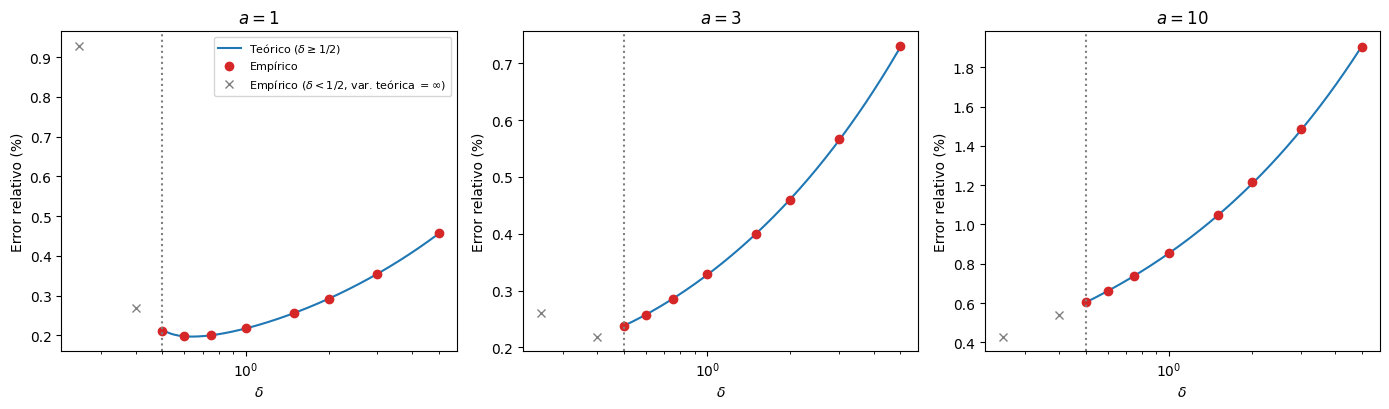

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.special import log_ndtr

# ----------------------------------------------------------
# Configuración
# f = N_2(0, C);  g_delta = N_2(b, delta*C),  b = (a, a)
# ----------------------------------------------------------
C = np.array([[4.0, -1.0], [-1.0, 4.0]])
Cinv = np.linalg.inv(C)
sigma, rho = 2.0, -0.25
a_list = [1, 3, 10]
delta_list = [0.25, 0.4, 0.5, 0.6, 0.75, 1.0, 1.5, 2.0, 3.0, 5.0]
n = 10**6

rng = np.random.default_rng(2026)
trapecio = getattr(np, "trapezoid", None) or np.trapz


def log_p_exacta(c):
    """log P(X1>=c, X2>=c) para X ~ N_2(0, C) (integral 1D en escala log)."""
    sc = sigma * np.sqrt(1 - rho**2)
    x = np.linspace(c, c + 60, 200001)
    log_f = stats.norm.logpdf(x, 0, sigma) + log_ndtr((rho * x - c) / sc)
    m = log_f.max()
    return m + np.log(trapecio(np.exp(log_f - m), x))


def log_M2(a, d):
    """log del segundo momento E_g[1_A w^2] (fórmula cerrada; inf si d < 1/2)."""
    if d < 0.5:
        return np.inf
    if d == 0.5:
        return np.log(9) - 2 * a**2 / 3 - np.log(16 * np.pi * np.sqrt(15) * a**2)
    c = 2 * a * np.sqrt(d / (2 * d - 1))
    return (2 * np.log(d) - np.log(2 * d - 1)
            + 2 * a**2 / (3 * (2 * d - 1)) + log_p_exacta(c))


def cuad(Y, M):
    """Forma cuadrática y' M y para cada fila de Y."""
    return np.einsum("ij,jk,ik->i", Y, M, Y)


# ----------------------------------------------------------
# Experimento: muestreo por importancia con distintos delta
# peso: w(y) = delta * exp( -y'C^{-1}y/2 + (y-b)'C^{-1}(y-b)/(2 delta) )
# ----------------------------------------------------------
filas = []
for a in a_list:
    b = np.array([a, a], dtype=float)
    p = np.exp(log_p_exacta(a))
    for d in delta_list:
        Y = rng.multivariate_normal(mean=b, cov=d * C, size=n)
        en_A = (Y[:, 0] >= a) & (Y[:, 1] >= a)
        log_w = (np.log(d) - 0.5 * cuad(Y, Cinv)
                 + cuad(Y - b, Cinv) / (2 * d))
        w = np.exp(log_w) * en_A                  # 1_A(Y) * f(Y)/g(Y)

        p_hat = w.mean()
        se = w.std(ddof=1) / np.sqrt(n)
        lM2 = log_M2(a, d)
        se_teo = np.sqrt(max(np.exp(lM2) - p**2, 0) / n) if np.isfinite(lM2) else np.inf

        filas.append({
            "a": a, "delta": d, "p exacta": p, "p_hat": p_hat,
            "SE est.": se, "SE teór.": se_teo,
            "error rel. emp.": se / p_hat if p_hat > 0 else np.nan,
            "error rel. teór.": se_teo / p,
            "|p_hat-p|/p": abs(p_hat - p) / p,
            "frac. en A": en_A.mean(),
            "ESS": w.sum()**2 / (w**2).sum() if w.sum() > 0 else 0.0,
        })

tabla = pd.DataFrame(filas)
pd.set_option("display.width", 250)
print(tabla.to_string(index=False, float_format=lambda x: f"{x:.4e}"))
print("\nNota: para delta < 1/2 la varianza teórica es infinita (SE teór. = inf)"
      " y el SE empírico no es confiable.")

# ----------------------------------------------------------
# Gráfica: error relativo (%) vs delta
# ----------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
ds_fino = np.linspace(0.505, 5, 400)
for ax, a in zip(axes, a_list):
    p = np.exp(log_p_exacta(a))
    teo = [np.sqrt((np.exp(log_M2(a, d)) - p**2) / n) / p for d in ds_fino]
    ax.plot(ds_fino, np.array(teo) * 100, "-", color="C0", label=r"Teórico ($\delta \geq 1/2$)")
    sub = tabla[tabla["a"] == a]
    ok = sub["delta"] >= 0.5
    ax.plot(sub.loc[ok, "delta"], sub.loc[ok, "error rel. emp."] * 100,
            "o", color="C3", label="Empírico")
    ax.plot(sub.loc[~ok, "delta"], sub.loc[~ok, "error rel. emp."] * 100,
            "x", color="gray", label=r"Empírico ($\delta<1/2$, var. teórica $=\infty$)")
    ax.axvline(0.5, color="gray", ls=":")
    ax.set_xscale("log")
    ax.set_xlabel(r"$\delta$")
    ax.set_ylabel("Error relativo (%)")
    ax.set_title(f"$a={a}$")
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.savefig("delta_error.png", dpi=200)
plt.show()